# Overload and prediction. Baseline and H1

This notebook runs the package `overload` in the repository `overload-prediction`. Every model, measure and decision rule comes from `ANALYSIS_PLAN.md`, frozen before the tests ran, and every result is logged in `STORY.md`.

**Colab.** Upload `overload-prediction.zip` and the study's data file `Updated_Choice_Overload.csv` to `/content`, then run the cells in order. Results already in the repository are loaded. Set `RECOMPUTE = True` to rerun the bootstrap (about 2 minutes for the baseline and 5 for H1 with two processes).

In [1]:
import os, sys, json, zipfile
from pathlib import Path

REPO = Path(os.environ.get("OVERLOAD_REPO", "/content/overload-prediction"))
DATA = Path(os.environ.get("OVERLOAD_DATA", "/content/Updated_Choice_Overload.csv"))
RECOMPUTE = False
JOBS = 2

if not REPO.exists() and Path("/content/overload-prediction.zip").exists():
    zipfile.ZipFile("/content/overload-prediction.zip").extractall("/content")
sys.path.insert(0, str(REPO / "src"))
os.chdir(REPO)

import overload
from overload.engine import plan_digest
print("package", overload.__version__, "| plan digest", plan_digest()[:16])

package 0.1.0 | plan digest f3b624d8c2500f4e


## 1. The rebuilt pipeline reproduces the earlier one

**Why.** Every later result rests on the new code, so it must first reproduce the earlier (AAMAS) pipeline from the raw data.

**How.** The test suite checks every measure and model on synthetic cases, then compares the rebuilt pipeline with the earlier one: rubric shares, attainable scores, per trial held out and fitted log scores and overlaps of QR, CL, DbS and MLBA, for the original sample and four bootstrap replicates.

In [2]:
import subprocess
env = dict(os.environ, OVERLOAD_DATA=str(DATA), PYTHONPATH=str(REPO / "src"))
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests"], cwd=REPO, env=env, capture_output=True, text=True)
print(r.stdout[-600:] or r.stderr[-600:])

..............................................                           [100%]



**Findings.**

1. Every test passed. Rubric shares match the earlier ones exactly, and per trial log scores and overlaps match within 1e-6 bits (largest difference 2.5e-8, the earlier optimizer's tolerance), for the original sample and for bootstrap replicates 0, 1, 499 and 999.
2. The published completeness values and their intervals are reproduced once each trial's attainable log score is held at its full sample value inside the bootstrap (plan, Amendment 1).

## 2. R0, the baseline

**Why.** The descriptive starting point. How far each one parameter model predicts unseen trials, with the comparison models averaged over rivals as well as summed.

**How.** Held out (each trial predicted from the other five) and fitted completeness, and held out overlap, per task and information level, with differences from CL and 1000 participant resamples.

In [3]:
from overload.experiments import baseline
out = REPO / "results" / "baseline"
if RECOMPUTE or not (out / "summary.json").exists():
    baseline.run(DATA, out, replicates=1000, jobs=JOBS)
print((out / "table_baseline.md").read_text())

| Task | Model | Held out completeness, % | Low | High | Fitted, % | Held out overlap, % | Completeness minus CL, points | Overlap minus CL, points |
|---|---|---|---|---|---|---|---|---|
| file | QR | 21.9 [14.3, 30.1] * | 12.4 [4.1, 21.6] * | 30.6 [20.5, 41.5] * | 23.9 | 55.0 | -7.7 [-11.7, -3.9] * | -3.2 [-4.2, -1.9] * |
| file | CL | 29.5 [20.2, 39.2] * | 29.1 [18.1, 42.5] * | 29.9 [19.1, 41.4] * | 32.9 | 58.2 |  |  |
| file | DbS_avg | 32.1 [22.4, 42.2] * | 30.2 [19.3, 42.7] * | 33.8 [21.7, 46.3] * | 33.5 | 58.7 | 2.6 [0.7, 4.4] * | 0.5 [0.0, 1.4] |
| file | MLBA_avg | 31.4 [22.2, 41.3] * | 30.2 [19.7, 42.1] * | 32.5 [20.6, 44.7] * | 32.2 | 58.4 | 1.8 [-0.9, 4.6] | 0.1 [-0.9, 1.4] |
| file | DbS_sum | 23.9 [16.1, 32.0] * | 19.3 [8.3, 31.0] * | 28.2 [17.6, 39.2] * | 25.5 | 54.7 | -5.6 [-10.2, -1.5] * | -3.5 [-4.2, -1.0] * |
| file | MLBA_sum | 22.6 [15.0, 30.2] * | 20.7 [11.4, 31.5] * | 24.3 [13.5, 35.7] * | 24.3 | 54.1 | -6.9 [-12.4, -2.2] * | -4.1 [-4.9, -1.4] * |
| laptop | QR |

**Findings.**

1. Held out completeness of CL was 29.5% [20.2, 39.2] for files and 50.3% [38.9, 62.0] for laptops, as published.
2. Averaged comparison scores predicted unseen trials at least as well as CL in both tasks. DbS_avg exceeded CL by 2.6 points [0.7, 4.4] for files and 5.1 [3.1, 7.3] for laptops, and MLBA_avg by 1.8 [-0.9, 4.6] and 6.9 [3.4, 11.0]. For laptops overlap rose with them, by 2.3 and 4.2 points.
3. Summing the comparisons over every rival instead cost 5.6 and 6.9 points against CL for files, so how sensitivity scales with set size matters. That is test A1a of H1.

## 3. H1, narrowing with set size

**Why.** The story's first claim. As options grow, do choices narrow (concentrate on fewer options than a model expects) or become noisier?

**How.** Three pre-specified tests (plan Section 7 with Amendment 2).
- B1, behavior. Effective options as a share of the set, observed against held out CL predictions sampled at the observed number of choices. Predicted, a negative mean gap and a negative slope per doubling of the options.
- A1a, algorithm. Sensitivity scaled by ((n - 1) / 7) to the power beta, with beta from -1 (noisier with more options) to +1 (sharper), for CL, DbS_avg and MLBA_avg. Predicted, beta +0.5 beats beta 0 and beta -0.5 loses to it.
- A1b, algorithm. Elimination by aspects with rubric weights against CL, 32 option trials minus 8 option trials.

# H1, narrowing with set size (development data)

## file

### A1a, set size scaling, held out completeness (%)

| Model | beta | Completeness | 8 | 16 | 32 | Overlap % | Minus beta 0 | Overlap minus beta 0 |
|---|---|---|---|---|---|---|---|---|
| CL | -1.0 | 28.4 [20.0, 37.0] * | 61.9 | 3.0 | 21.1 | 57.6 | -1.1 [-5.5, 2.8] | -0.6 [-2.3, 1.6] |
| CL | -0.5 | 29.9 [21.1, 39.1] * | 61.7 | -5.8 | 32.5 | 58.8 | 0.4 [-2.0, 2.5] | 0.5 [-1.0, 1.6] |
| CL | +0.0 | 29.5 [20.2, 39.2] * | 54.0 | -7.7 | 39.3 | 58.2 |  |  |
| CL | +0.5 | 26.6 [17.8, 35.5] * | 38.0 | 0.3 | 38.4 | 56.4 | -3.0 [-5.4, -0.8] * | -1.8 [-2.4, -0.4] * |
| CL | +1.0 | 22.2 [14.3, 30.4] * | 21.9 | 6.8 | 35.1 | 54.6 | -7.3 [-12.1, -3.2] * | -3.6 [-4.5, -1.5] * |
| DbS_avg | -1.0 | 27.8 [19.3, 37.0] * | 53.3 | 12.9 | 18.5 | 56.8 | -4.3 [-9.3, 0.3] | -2.0 [-3.9, -0.2] * |
| DbS_avg | -0.5 | 31.3 [22.1, 41.0] * | 55.9 | 8.3 | 29.4 | 58.6 | -0.8 [-3.5, 1.5] | -0.1 [-1.7, 0.7] |
| DbS_avg | +0.0 | 32.1 [22.4, 42.2] * | 52.4 | 5.8

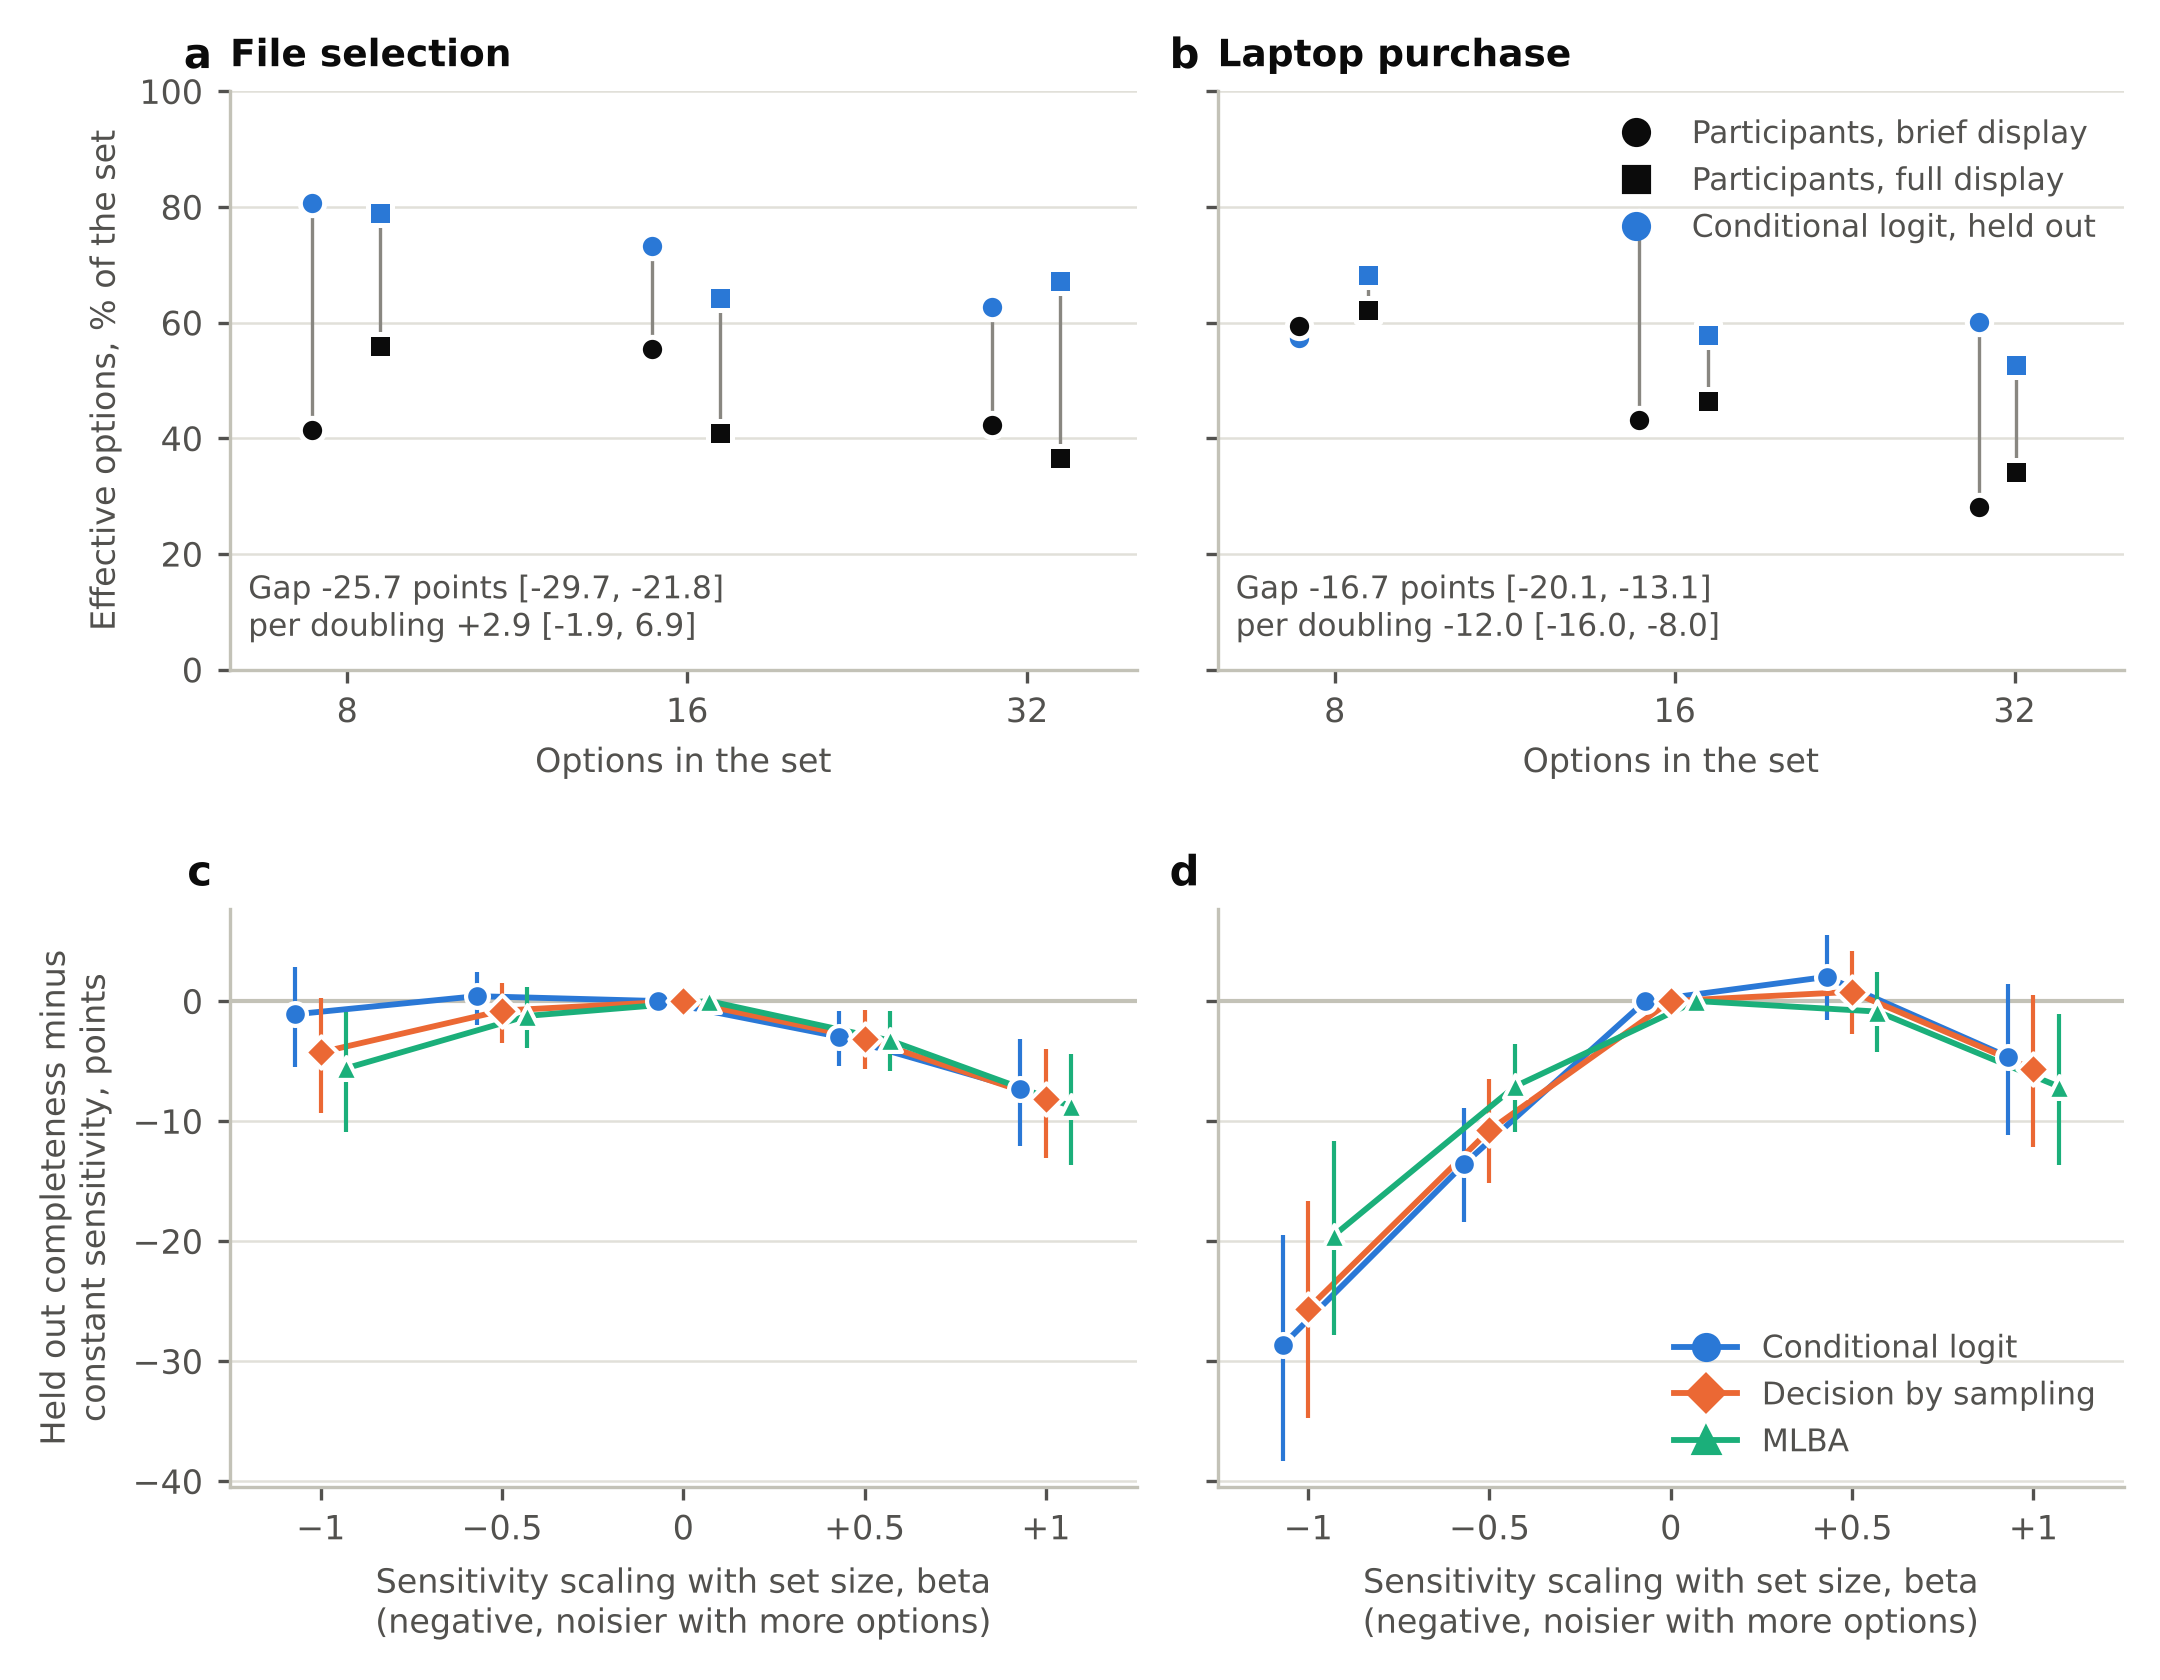

In [4]:
from overload.experiments import h1_narrowing
from overload.figures import figure_h1
from IPython.display import Image, display
out = REPO / "results" / "h1"
if RECOMPUTE or not (out / "summary.json").exists():
    h1_narrowing.run(DATA, out, replicates=1000, jobs=JOBS)
summary = json.loads((out / "summary.json").read_text())
figure_h1(summary, out / "fig_h1_narrowing")
print((out / "table_h1.md").read_text())
display(Image(filename=str(out / "fig_h1_narrowing.png"), width=900))

**Findings.**

1. People narrowed. Their choices were more concentrated than held out CL predictions in 11 of the 12 trials, by 25.7 points of the set for files [-29.7, -21.8] and 16.7 for laptops [-20.1, -13.1]. For laptops the gap widened by 12.0 points with each doubling of the options [-16.0, -8.0], for files it did not (+2.9 [-1.9, 6.9]). B1 supports H1 for laptops only.
2. The noise account failed. Lowering sensitivity as sets grow (beta -0.5) cut laptop completeness by 13.6 points [-18.4, -8.9] and left files unchanged (+0.4 [-2.0, 2.5]), with the same pattern in all three model families.
3. Uniform sharpening failed too. Raising sensitivity with set size (beta +0.5) lowered file completeness by 3.0 points [-5.4, -0.8] and changed laptops by +2.0 [-1.6, 5.5]. A1a does not support H1 in either task.
4. Screening on the rubric's attributes in the rubric's order predicted badly, 32 to 34 points below CL in both tasks. Its deficit shrank from 8 to 32 file options, which passes the A1b rule for files, but it never overtook CL.

**Story.** Narrowing is real, but it is not a sharper version of the valuation the models use. People concentrated on options for reasons the coded attributes and the rubric do not carry, which moves the story to H3 (what people screen on) and H4 (whether that helps or hurts).